# Garbage Detection — YOLOv8 + ResNet101 Inference

This notebook performs inference only. It does not download the Roboflow dataset or train either model.

**Pipeline:** Input image → YOLOv8 detections → crop each box → ResNet101 classification → draw the original boxes with final ResNet labels.

Run the cells from top to bottom. Update the two model paths and confirm the ResNet class order before running.

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
# 1. Mount Google Drive and import libraries
from google.colab import drive
drive.mount('/content/drive')

import os
import time
import torch
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display
from torchvision import models, transforms
from ultralytics import YOLO

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda


In [ ]:
# 2. Set model paths and class names

YOLO_WEIGHTS = "/content/drive/MyDrive/trash_comparison/best.pt"
RESNET_WEIGHTS = "/content/drive/MyDrive/trash_comparison/best_resnet101.pth"

# IMPORTANT:
# This order MUST exactly match the class_to_idx order used when training ResNet.
# Confirm it from train_dataset.class_to_idx in your original training notebook.
RESNET_CLASSES = ["glass", "metal", "paper", "plastic", "waste"]

CONF_THRESHOLD = 0.25
NMS_IOU_THRESHOLD = 0.70
CLASSIFIER_IMAGE_SIZE = 224

assert os.path.isfile(YOLO_WEIGHTS), f"YOLO weights not found: {YOLO_WEIGHTS}"
assert os.path.isfile(RESNET_WEIGHTS), f"ResNet weights not found: {RESNET_WEIGHTS}"

print("Model files found.")
print("ResNet class order:", RESNET_CLASSES)

Model files found.
ResNet class order: ['glass', 'metal', 'paper', 'plastic', 'waste']


In [ ]:
# 3. Load trained YOLOv8 model

yolo_model = YOLO(YOLO_WEIGHTS)

YOLO_NAMES = yolo_model.names
if isinstance(YOLO_NAMES, dict):
    YOLO_NAMES = {int(k): str(v) for k, v in YOLO_NAMES.items()}
else:
    YOLO_NAMES = {i: str(v) for i, v in enumerate(YOLO_NAMES)}

print("YOLO classes:", YOLO_NAMES)

assert len(RESNET_CLASSES) == len(YOLO_NAMES), (
    "YOLO and ResNet must have the same number of classes."
)
assert [YOLO_NAMES[i].lower() for i in range(len(YOLO_NAMES))] == [
    name.lower() for name in RESNET_CLASSES
], "Class order mismatch. Set RESNET_CLASSES to the exact ResNet training order."

print("YOLO model loaded and class order checked.")

YOLO classes: {0: 'Glass', 1: 'Metal', 2: 'Paper', 3: 'Plastic', 4: 'Waste'}
YOLO model loaded and class order checked.


In [ ]:
# 4. Load trained ResNet101 classifier

checkpoint = torch.load(
    RESNET_WEIGHTS,
    map_location="cpu",
    weights_only=True
)

# Support either a plain state_dict or a checkpoint containing one.
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

# Remove DataParallel prefix if the model was saved using DataParallel.
state_dict = {
    (key[7:] if key.startswith("module.") else key): value
    for key, value in state_dict.items()
}

if "fc.weight" not in state_dict:
    raise ValueError("Could not find fc.weight in the checkpoint. Check the saved model format.")

num_classes = state_dict["fc.weight"].shape[0]
assert num_classes == len(RESNET_CLASSES), (
    f"Checkpoint has {num_classes} outputs, but RESNET_CLASSES has {len(RESNET_CLASSES)} names."
)

resnet_model = models.resnet101(weights=None)
resnet_model.fc = torch.nn.Linear(resnet_model.fc.in_features, num_classes)
resnet_model.load_state_dict(state_dict, strict=True)
resnet_model = resnet_model.to(DEVICE)
resnet_model.eval()

print("ResNet101 loaded successfully.")
print("Output classes:", RESNET_CLASSES)

ResNet101 loaded successfully.
Output classes: ['glass', 'metal', 'paper', 'plastic', 'waste']


In [ ]:
# 5. Define preprocessing and crop-classification function
# These transformations must match the preprocessing used during ResNet training.

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@torch.inference_mode()
def classify_crop(crop):
    crop = crop.convert("RGB")
    input_tensor = resnet_transform(crop).unsqueeze(0).to(DEVICE)

    logits = resnet_model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)

    confidence, class_index = probabilities.max(dim=1)
    predicted_class = RESNET_CLASSES[class_index.item()]

    return predicted_class, float(confidence.item())

In [ ]:

# 6. YOLOv8 detection followed by ResNet101 verification

def run_yolo_resnet(image):

    image = image.convert("RGB")

    result = yolo_model.predict(
        source=image,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is None:
        return predictions

    image_width, image_height = image.size

    for detected_box in result.boxes:

        # Step 1: Get YOLO bounding box and prediction
        box_xyxy = (
            detected_box.xyxy[0]
            .detach()
            .cpu()
            .numpy()
            .astype(float)
        )

        yolo_confidence = float(detected_box.conf.item())
        yolo_class_id = int(detected_box.cls.item())
        yolo_class_name = YOLO_NAMES[yolo_class_id]

        x1, y1, x2, y2 = box_xyxy

        x1 = max(0, min(int(x1), image_width - 1))
        y1 = max(0, min(int(y1), image_height - 1))
        x2 = max(0, min(int(x2), image_width))
        y2 = max(0, min(int(y2), image_height))

        if x2 <= x1 or y2 <= y1:
            continue

        # Step 2: Crop detected object
        object_crop = image.crop((x1, y1, x2, y2))

        # Step 3: Classify crop using ResNet101
        resnet_class_name, resnet_confidence = classify_crop(object_crop)

        # Step 4: Compare YOLO and ResNet predictions
        if yolo_class_name.strip().lower() != resnet_class_name.strip().lower():

            print(
                f"REJECTED: YOLO={yolo_class_name}, "
                f"ResNet={resnet_class_name}"
            )

            continue

        # Step 5: Retain only matching predictions
        predictions.append({
            "box": (x1, y1, x2, y2),
            "yolo_class": yolo_class_name,
            "yolo_confidence": yolo_confidence,
            "resnet_class": resnet_class_name,
            "resnet_confidence": resnet_confidence,
            "final_class": yolo_class_name
        })

        print(
            f"ACCEPTED: {yolo_class_name} | "
            f"YOLO={yolo_confidence:.3f} | "
            f"ResNet={resnet_confidence:.3f}"
        )

    return predictions


print("YOLO + ResNet verification function is ready.")


YOLO + ResNet verification function is ready.


In [ ]:
# 7. YOLO-only inference (Approach 1)

def run_approach1(image):

    image = image.convert("RGB")

    result = yolo_model.predict(
        source=image,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is None:
        return predictions

    for detected_box in result.boxes:

        box_xyxy = (
            detected_box.xyxy[0]
            .detach()
            .cpu()
            .numpy()
            .astype(float)
        )

        x1, y1, x2, y2 = box_xyxy

        predictions.append({
            "box": (int(x1), int(y1), int(x2), int(y2)),
            "class_id": int(detected_box.cls.item()),
            "class_name": YOLO_NAMES[int(detected_box.cls.item())],
            "confidence": float(detected_box.conf.item())
        })

    return predictions


print("YOLO-only inference function is ready.")

YOLO-only inference function is ready.


In [ ]:

# 7. Define YOLO-only inference and reusable image testing function

def run_approach1(image):
    """Approach 1: YOLOv8 only."""

    result = yolo_model.predict(
        source=image.convert("RGB"),
        conf=CONF_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is None:
        return predictions

    width, height = image.size

    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

        x1 = max(0, min(int(x1), width - 1))
        y1 = max(0, min(int(y1), height - 1))
        x2 = max(0, min(int(x2), width))
        y2 = max(0, min(int(y2), height))

        if x2 <= x1 or y2 <= y1:
            continue

        class_id = int(box.cls.item())

        predictions.append({
            "box": (x1, y1, x2, y2),
            "class_name": YOLO_NAMES[class_id],
            "confidence": float(box.conf.item())
        })

    return predictions


def test_image(image_path):

    with Image.open(image_path) as img:
        input_image = img.convert("RGB")

    # Approach 1: YOLO only
    start = time.perf_counter()
    yolo_predictions = run_approach1(input_image)
    yolo_time = time.perf_counter() - start

    # Approach 2: YOLO + ResNet101
    start = time.perf_counter()
    resnet_predictions = run_yolo_resnet(input_image)
    resnet_time = time.perf_counter() - start

    # Create output images
    yolo_output = input_image.copy()
    resnet_output = input_image.copy()

    draw_yolo = ImageDraw.Draw(yolo_output)
    draw_resnet = ImageDraw.Draw(resnet_output)

    # Draw YOLO-only results
    for pred in yolo_predictions:
        x1, y1, x2, y2 = pred["box"]

        label = f'{pred["class_name"]} {pred["confidence"]:.2f}'

        draw_yolo.rectangle(
            (x1, y1, x2, y2), outline="red", width=3
        )
        draw_yolo.text(
            (x1, max(0, y1 - 18)), label, fill="red"
        )

    # Draw YOLO + ResNet results
    for pred in resnet_predictions:
        x1, y1, x2, y2 = pred["box"]

        label = (
            f'{pred["final_class"]} '
            f'(R:{pred["resnet_confidence"]:.2f})'
        )

        draw_resnet.rectangle(
            (x1, y1, x2, y2), outline="lime", width=3
        )
        draw_resnet.text(
            (x1, max(0, y1 - 18)), label, fill="lime"
        )

    # Display comparison
    print("APPROACH 1: YOLO ONLY")
    print("Objects detected:", len(yolo_predictions))
    print(f"Inference time: {yolo_time:.3f} seconds")
    display(yolo_output)

    print("\nAPPROACH 2: YOLO + RESNET101")
    print("Objects classified:", len(resnet_predictions))
    print(f"Inference time: {resnet_time:.3f} seconds")
    display(resnet_output)

    # Save results
    yolo_output.save("/content/yolo_only_output.jpg")
    resnet_output.save("/content/yolo_resnet_output.jpg")

    return yolo_predictions, resnet_predictions


Saving WhatsApp Image 2026-10-06 at 2.07.08 PM.jpeg to WhatsApp Image 2026-10-06 at 2.07.08 PM (1).jpeg
REJECTED: YOLO=Metal, ResNet=plastic
REJECTED: YOLO=Plastic, ResNet=waste
ACCEPTED: Plastic | YOLO=0.504 | ResNet=0.989
ACCEPTED: Plastic | YOLO=0.399 | ResNet=0.988
ACCEPTED: Paper | YOLO=0.288 | ResNet=0.901
ACCEPTED: Metal | YOLO=0.265 | ResNet=0.461
REJECTED: YOLO=Paper, ResNet=plastic
APPROACH 1: YOLO ONLY
Objects detected: 7
Inference time: 0.023 seconds


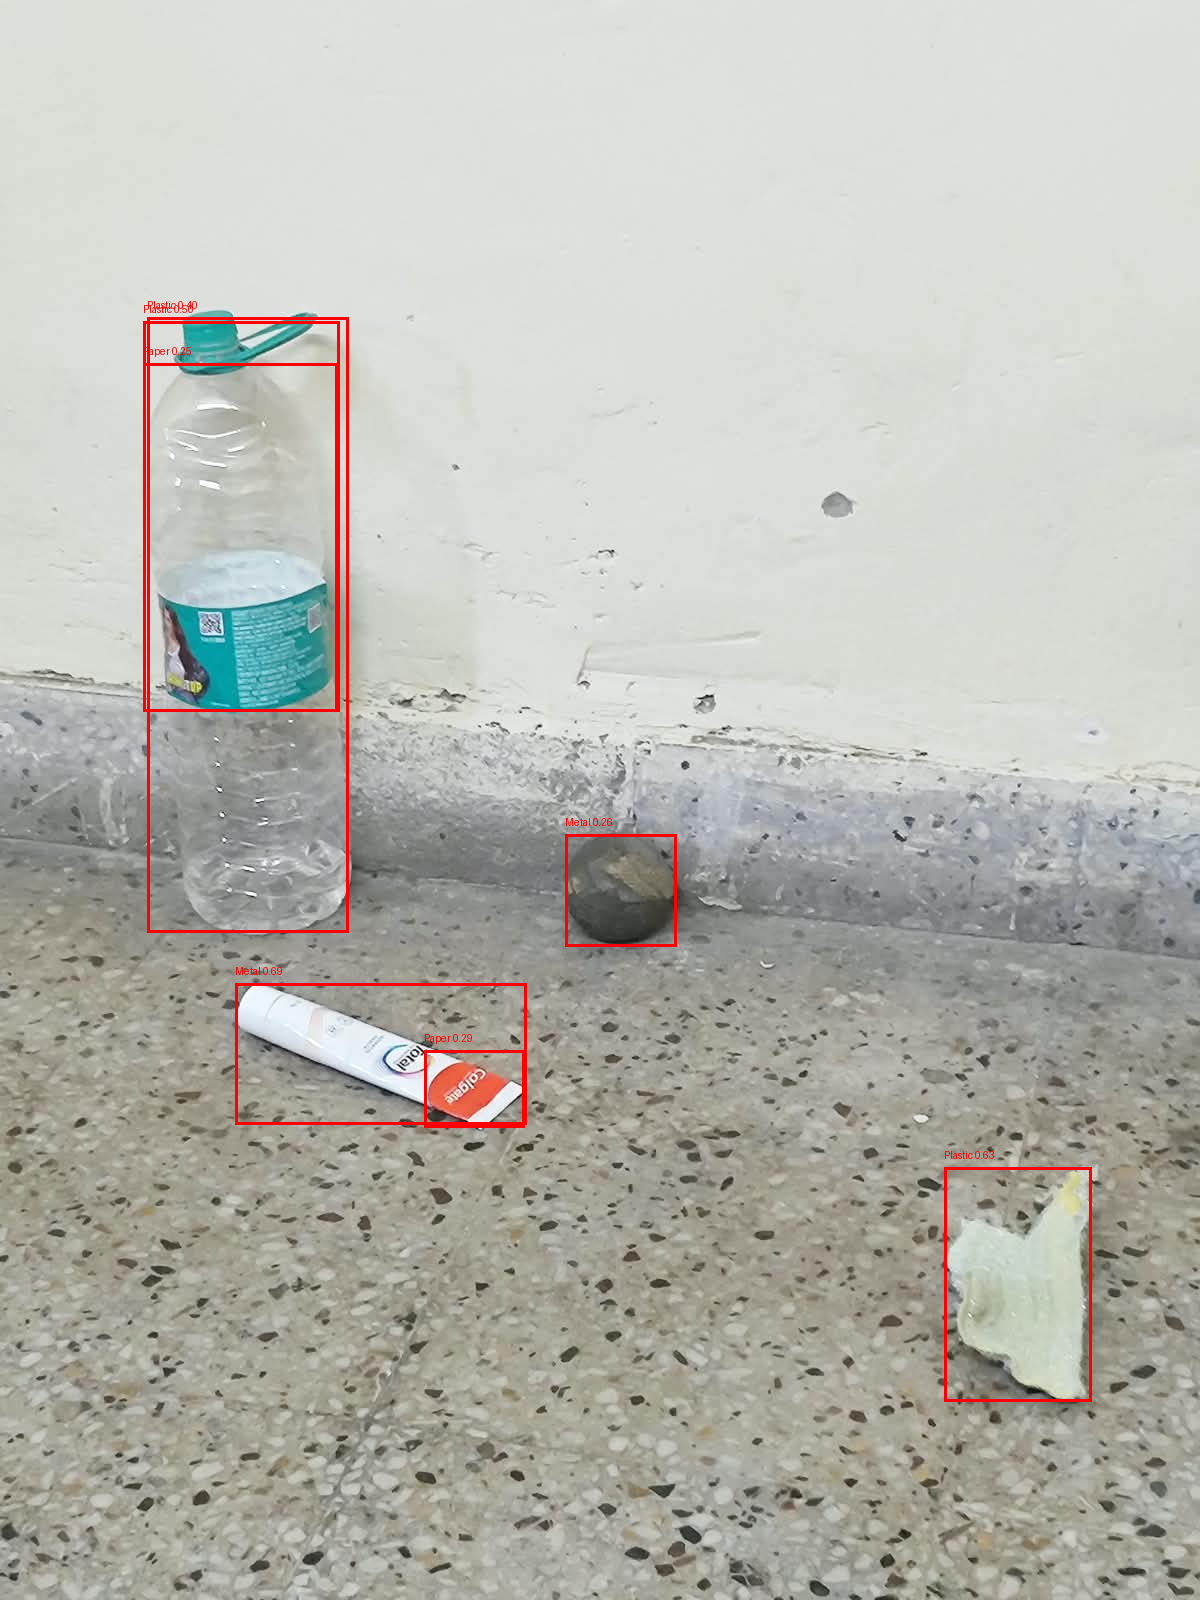


APPROACH 2: YOLO + RESNET101
Objects classified: 4
Inference time: 0.190 seconds


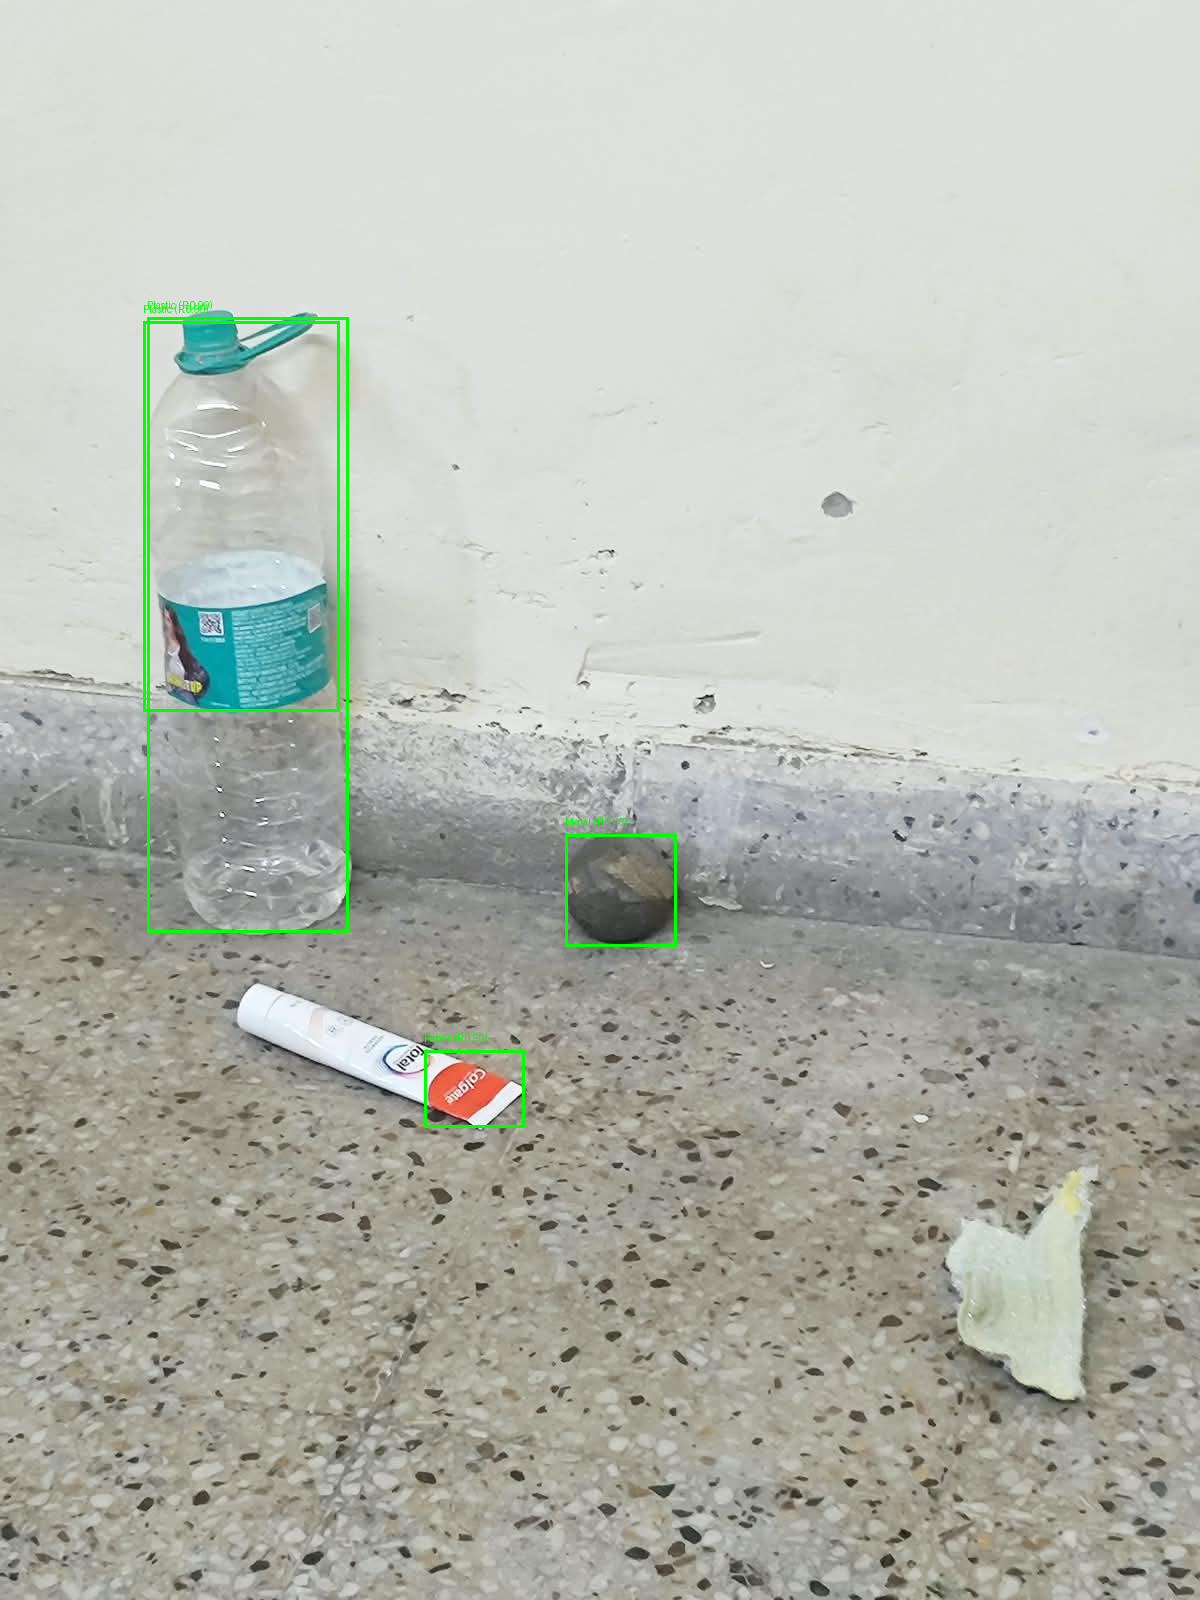

In [ ]:

# 8. Upload and test a new image

from google.colab import files

uploaded = files.upload()

if uploaded:
    image_path = next(iter(uploaded))

    yolo_preds, resnet_preds = test_image(image_path)


In [ ]:
!pip install roboflow

from roboflow import Roboflow

rf = Roboflow(api_key="UhDElvfr70an8tHhDx01")

project = rf.workspace(
    "trash-dataset-for-oriented-bounded-box"
).project("trash-detection-1fjjc")

version = project.version(14)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Trash-Detection-14 in yolov8:: 100%|██████████| 13578/13578 [00:03<00:00, 3963.37it/s]


In [ ]:

# ============================================================
# DATASET PATH CONFIGURATION
# ============================================================

import os

# Main dataset directory downloaded by Roboflow
DATASET_PATH = dataset.location

# Test dataset directories
TEST_IMAGES = os.path.join(DATASET_PATH, "test", "images")
TEST_LABELS = os.path.join(DATASET_PATH, "test", "labels")

print("Dataset location:", DATASET_PATH)
print("Test images path:", TEST_IMAGES)
print("Test labels path:", TEST_LABELS)

# Verify directories
assert os.path.isdir(TEST_IMAGES), "Test images directory not found!"
assert os.path.isdir(TEST_LABELS), "Test labels directory not found!"

print("\nDataset paths configured successfully!")

print("Test images:", len(os.listdir(TEST_IMAGES)))
print("Test labels:", len(os.listdir(TEST_LABELS)))


Dataset location: /content/Trash-Detection-14
Test images path: /content/Trash-Detection-14/test/images
Test labels path: /content/Trash-Detection-14/test/labels

Dataset paths configured successfully!
Test images: 110
Test labels: 110


In [ ]:

# ============================================================
# EVALUATION: YOLOv8 vs YOLOv8 + ResNet101 VERIFICATION
# Metrics: Precision, Recall, AP@50, mAP@50, mAP@50-95
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from collections import defaultdict

# ------------------------------------------------------------
# 1. CHECK DATASET PATHS AND MODELS
# ------------------------------------------------------------

assert os.path.isdir(TEST_IMAGES), "TEST_IMAGES path is incorrect."
assert os.path.isdir(TEST_LABELS), "TEST_LABELS path is incorrect."

assert "yolo_model" in globals(), "YOLO model is not loaded."
assert "classify_crop" in globals(), "classify_crop() is not defined."

# Get YOLO class names
if isinstance(yolo_model.names, dict):
    CLASS_NAMES = {
        int(k): str(v) for k, v in yolo_model.names.items()
    }
else:
    CLASS_NAMES = {
        i: str(v) for i, v in enumerate(yolo_model.names)
    }

NUM_CLASSES = len(CLASS_NAMES)

# Check that ResNet and YOLO use the same class names.
assert set(c.lower() for c in RESNET_CLASSES) == set(
    c.lower() for c in CLASS_NAMES.values()
), "YOLO and ResNet class names do not match."

CLASS_TO_ID = {
    name.lower(): class_id
    for class_id, name in CLASS_NAMES.items()
}

print("Classes:", CLASS_NAMES)


# ------------------------------------------------------------
# 2. GET TEST IMAGES
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted([
    p for p in Path(TEST_IMAGES).iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

assert len(image_paths) > 0, "No test images found."

print("Total test images:", len(image_paths))


# ------------------------------------------------------------
# 3. LOAD GROUND-TRUTH ANNOTATIONS
# Supports:
# - YOLO bounding box: class x_center y_center width height
# - Polygon: class x1 y1 x2 y2 x3 y3 ...
# Coordinates are normalized between 0 and 1.
# ------------------------------------------------------------

def load_ground_truth(image_path):

    label_path = Path(TEST_LABELS) / (image_path.stem + ".txt")

    with Image.open(image_path) as im:
        width, height = im.size

    gt_boxes = []

    if not label_path.exists():
        return gt_boxes

    for line_number, line in enumerate(
        label_path.read_text().splitlines(), start=1
    ):

        if not line.strip():
            continue

        values = list(map(float, line.split()))

        class_id = int(values[0])

        if class_id not in CLASS_NAMES:
            raise ValueError(
                f"Invalid class ID in {label_path}, line {line_number}"
            )

        coords = values[1:]

        if len(coords) == 4:
            # Standard YOLO normalized xywh format
            xc, yc, bw, bh = coords

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

        elif len(coords) >= 6 and len(coords) % 2 == 0:
            # Polygon format: convert polygon to enclosing rectangle
            points = np.array(coords).reshape(-1, 2)

            x1 = points[:, 0].min() * width
            y1 = points[:, 1].min() * height
            x2 = points[:, 0].max() * width
            y2 = points[:, 1].max() * height

        else:
            raise ValueError(
                f"Unexpected annotation format in {label_path}, "
                f"line {line_number}"
            )

        gt_boxes.append({
            "box": np.array([x1, y1, x2, y2], dtype=float),
            "class_id": class_id
        })

    return gt_boxes


# ------------------------------------------------------------
# 4. IOU CALCULATION
# ------------------------------------------------------------

def box_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0


# ------------------------------------------------------------
# 5. RUN BOTH APPROACHES ON THE SAME YOLO DETECTIONS
# Approach 1: Keep all YOLO detections.
# Approach 2: Keep only YOLO/ResNet class matches.
# ------------------------------------------------------------

predictions_1 = []
predictions_2 = []
ground_truths = []

yolo_times = []
combined_times = []

for image_index, image_path in enumerate(image_paths):

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    gt = load_ground_truth(image_path)

    # Run YOLO once; use the same detections for both approaches.
    start = time.perf_counter()

    result = yolo_model.predict(
        source=image,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        verbose=False
    )[0]

    yolo_elapsed = time.perf_counter() - start
    yolo_times.append(yolo_elapsed)

    image_pred_1 = []
    image_pred_2 = []

    verification_start = time.perf_counter()

    if result.boxes is not None:

        image_width, image_height = image.size

        for detected_box in result.boxes:

            coords = (
                detected_box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .astype(float)
            )

            x1, y1, x2, y2 = coords

            x1 = max(0, min(int(x1), image_width - 1))
            y1 = max(0, min(int(y1), image_height - 1))
            x2 = max(0, min(int(x2), image_width))
            y2 = max(0, min(int(y2), image_height))

            if x2 <= x1 or y2 <= y1:
                continue

            yolo_class_id = int(detected_box.cls.item())
            yolo_class_name = CLASS_NAMES[yolo_class_id]
            yolo_confidence = float(detected_box.conf.item())

            # Same YOLO prediction is used in Approach 1.
            prediction = {
                "box": np.array([x1, y1, x2, y2], dtype=float),
                "class_id": yolo_class_id,
                "confidence": yolo_confidence
            }

            image_pred_1.append(prediction)

            # ResNet verification for Approach 2.
            crop = image.crop((x1, y1, x2, y2))

            resnet_class_name, resnet_confidence = classify_crop(crop)

            # Retain only if YOLO and ResNet predict the same class.
            if (
                yolo_class_name.strip().lower()
                == resnet_class_name.strip().lower()
            ):

                image_pred_2.append(prediction)

    verification_elapsed = time.perf_counter() - verification_start

    # Approach 2 total time = YOLO detection + ResNet verification.
    combined_times.append(yolo_elapsed + verification_elapsed)

    predictions_1.append(image_pred_1)
    predictions_2.append(image_pred_2)
    ground_truths.append(gt)

    if (image_index + 1) % 25 == 0 or image_index + 1 == len(image_paths):
        print(
            f"Processed {image_index + 1}/{len(image_paths)} images"
        )


# ------------------------------------------------------------
# 6. PRECISION AND RECALL AT A GIVEN IOU THRESHOLD
# ------------------------------------------------------------

def calculate_precision_recall(
    all_predictions, all_ground_truth, iou_threshold=0.50
):

    TP = FP = FN = 0

    for predictions, gt_list in zip(
        all_predictions, all_ground_truth
    ):

        matched_gt = set()

        sorted_predictions = sorted(
            predictions,
            key=lambda p: p["confidence"],
            reverse=True
        )

        for pred in sorted_predictions:

            best_iou = 0
            best_gt_index = None

            for gt_index, gt in enumerate(gt_list):

                if gt_index in matched_gt:
                    continue

                if pred["class_id"] != gt["class_id"]:
                    continue

                iou = box_iou(pred["box"], gt["box"])

                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = gt_index

            if (
                best_gt_index is not None
                and best_iou >= iou_threshold
            ):
                TP += 1
                matched_gt.add(best_gt_index)
            else:
                FP += 1

        FN += len(gt_list) - len(matched_gt)

    precision = TP / (TP + FP) if (TP + FP) else 0.0
    recall = TP / (TP + FN) if (TP + FN) else 0.0

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall
    }


# ------------------------------------------------------------
# 7. AP CALCULATION FOR EACH CLASS
# ------------------------------------------------------------

def compute_ap_for_class(
    all_predictions,
    all_ground_truth,
    class_id,
    iou_threshold
):

    gt_by_image = {}
    total_gt = 0

    for image_index, gt_list in enumerate(all_ground_truth):

        boxes = [
            gt["box"] for gt in gt_list
            if gt["class_id"] == class_id
        ]

        gt_by_image[image_index] = boxes
        total_gt += len(boxes)

    if total_gt == 0:
        return np.nan

    detections = []

    for image_index, pred_list in enumerate(all_predictions):

        for pred in pred_list:

            if pred["class_id"] == class_id:
                detections.append((
                    pred["confidence"],
                    image_index,
                    pred["box"]
                ))

    detections.sort(key=lambda x: x[0], reverse=True)

    matched = {
        image_index: set()
        for image_index in gt_by_image
    }

    tp_list = []
    fp_list = []

    for confidence, image_index, pred_box in detections:

        gt_boxes = gt_by_image[image_index]

        best_iou = 0
        best_gt_index = None

        for gt_index, gt_box in enumerate(gt_boxes):

            if gt_index in matched[image_index]:
                continue

            iou = box_iou(pred_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt_index = gt_index

        if (
            best_gt_index is not None
            and best_iou >= iou_threshold
        ):

            tp_list.append(1)
            fp_list.append(0)
            matched[image_index].add(best_gt_index)

        else:
            tp_list.append(0)
            fp_list.append(1)

    if not tp_list:
        return 0.0

    tp_cumulative = np.cumsum(tp_list)
    fp_cumulative = np.cumsum(fp_list)

    recalls = tp_cumulative / total_gt
    precisions = tp_cumulative / (tp_cumulative + fp_cumulative)

    # Interpolated precision envelope
    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([0.0], precisions, [0.0]))

    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])

    changes = np.where(mrec[1:] != mrec[:-1])[0]

    ap = np.sum(
        (mrec[changes + 1] - mrec[changes])
        * mpre[changes + 1]
    )

    return float(ap)


# ------------------------------------------------------------
# 8. CALCULATE AP50, mAP50 AND mAP50-95
# ------------------------------------------------------------

def calculate_ap_metrics(all_predictions, all_ground_truth):

    classes_present = sorted({
        gt["class_id"]
        for gt_list in all_ground_truth
        for gt in gt_list
    })

    ap_per_class = {}

    for class_id in classes_present:

        ap = compute_ap_for_class(
            all_predictions,
            all_ground_truth,
            class_id,
            0.50
        )

        ap_per_class[CLASS_NAMES[class_id]] = ap

    map50 = np.nanmean(list(ap_per_class.values()))

    # AP averaged across IoU thresholds 0.50 to 0.95.
    iou_thresholds = np.arange(0.50, 0.951, 0.05)

    all_aps = []

    for threshold in iou_thresholds:

        for class_id in classes_present:

            ap = compute_ap_for_class(
                all_predictions,
                all_ground_truth,
                class_id,
                float(threshold)
            )

            all_aps.append(ap)

    map50_95 = np.nanmean(all_aps)

    return ap_per_class, float(map50), float(map50_95)


# ------------------------------------------------------------
# 9. FINAL METRIC COMPARISON
# ------------------------------------------------------------

pr_1 = calculate_precision_recall(
    predictions_1, ground_truths
)

pr_2 = calculate_precision_recall(
    predictions_2, ground_truths
)

ap_1, map50_1, map50_95_1 = calculate_ap_metrics(
    predictions_1, ground_truths
)

ap_2, map50_2, map50_95_2 = calculate_ap_metrics(
    predictions_2, ground_truths
)

comparison = pd.DataFrame(
    [
        {
            "Precision": pr_1["Precision"],
            "Recall": pr_1["Recall"],
            "mAP@50": map50_1,
            "mAP@50-95": map50_95_1,
            "Average time (sec/image)": np.mean(yolo_times),
            "TP": pr_1["TP"],
            "FP": pr_1["FP"],
            "FN": pr_1["FN"]
        },
        {
            "Precision": pr_2["Precision"],
            "Recall": pr_2["Recall"],
            "mAP@50": map50_2,
            "mAP@50-95": map50_95_2,
            "Average time (sec/image)": np.mean(combined_times),
            "TP": pr_2["TP"],
            "FP": pr_2["FP"],
            "FN": pr_2["FN"]
        }
    ],
    index=[
        "Approach 1: YOLOv8",
        "Approach 2: YOLOv8 + ResNet101 Verification"
    ]
)

print("\n========== OVERALL METRIC COMPARISON ==========")
display(comparison.round(4))

print("\n========== PER-CLASS AP@50 ==========")

ap_comparison = pd.DataFrame({
    "YOLOv8 AP@50": ap_1,
    "YOLOv8 + ResNet101 AP@50": ap_2
})

display(ap_comparison.round(4))

# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/garbage_detection_results"
os.makedirs(output_dir, exist_ok=True)

comparison.to_csv(
    os.path.join(output_dir, "approach_metrics_comparison.csv")
)

ap_comparison.to_csv(
    os.path.join(output_dir, "per_class_ap_comparison.csv")
)

print("\nResults saved to:", output_dir)


Classes: {0: 'Glass', 1: 'Metal', 2: 'Paper', 3: 'Plastic', 4: 'Waste'}
Total test images: 110
Processed 25/110 images
Processed 50/110 images
Processed 75/110 images
Processed 100/110 images
Processed 110/110 images

========== OVERALL METRIC COMPARISON ==========


,Precision,Recall,mAP@50,mAP@50-95,Average time (sec/image),TP,FP,FN
Approach 1: YOLOv8,0.6571,0.5257,0.4678,0.4338,0.0107,92,48,83
Approach 2: YOLOv8 + ResNet101 Verification,0.8980,0.5029,0.4533,0.4193,0.0304,88,10,87



========== PER-CLASS AP@50 ==========


,YOLOv8 AP@50,YOLOv8 + ResNet101 AP@50
Glass,0.4651,0.4500
Metal,0.6270,0.6376
Paper,0.6019,0.5556
Plastic,0.6452,0.6235
Waste,0.0000,0.0000



Results saved to: /content/drive/MyDrive/garbage_detection_results


## Important checks

- **ResNet class order:** `RESNET_CLASSES` must match the exact `class_to_idx` mapping used during ResNet training. Do not assume the order from YOLO unless you verified it.
- **Preprocessing:** Resize and normalization must match the ResNet training transforms.
- **Final label:** This notebook uses ResNet's class as the final label, while retaining YOLO's class and confidence in the printed comparison.
- **Bounding boxes:** The boxes still come from YOLO. ResNet is a crop classifier; it does not refine box coordinates.
- **Interpretation:** ResNet confidence is a softmax score, not a calibrated probability.
- **No agreement filtering:** A detection is not discarded just because YOLO and ResNet predict different classes.